<a href="https://colab.research.google.com/github/moistvonlipwig/cteli-27-13001506-DE-JS/blob/main/cteli_27_13001506_DE_JS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Project Analysis Summary

- **Project Focus:** We have successfully loaded raw, continuous miniSEED streams (`SEP01.mseed`, `SEP02.mseed`, `SEP03.mseed`) corresponding to monitoring networks at Mt. St. Helens.
- **Data Engineering:** Developed a structured, relational SQL schema containing `networks`, `stations`, and `traces` with standard constraints (Primary Keys, Foreign Keys, uniqueness and sample checks). Coordinates and site metrics for active stations were enriched by querying the EarthScope FDSN API.
- **Automation & Classification:** Implemented trace statistics rules to programmatically classify the streams into dynamic categories (*Granular Segments*, *Continuous Continuation*, and *Seismic Events Collection*).
- **Visualizations:** Deployed an interactive, high-contrast dashboard featuring station mapping with Esri World Topographic tiles and dynamic dayplot helicorders compiled cleanly into a single, cohesive interface.
```

## Project Overview
This notebook demonstrates a complete end-to-end seismological analysis pipeline. We ingest raw miniSEED files, populate a validated relational database, enrich our stations using the EarthScope FDSN station API, and compile an interactive web dashboard containing dynamic classifications, metadata summaries, topographic maps, and helicorder dayplots.

In [67]:
# =====================================================================
# Environment Setup & Library Initialization
# =====================================================================

# Install key external dependencies:
# - ObsPy: A Python toolbox for seismology, used here to read miniSEED streams and plot helicorders.
# - Folium: A Leaflet.js-based mapping library to build our interactive station maps.
!pip install -q obspy folium

# Standard Library Imports
import base64
import io
import sqlite3

# Third-Party Seismology and Mapping Imports
import folium
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from obspy import read
from obspy.clients.fdsn import Client

In [68]:
# =====================================================================
# Data Acquisition: Importing Raw Seismological Data
# =====================================================================
# The required miniSEED data files (SEP01, SEP02, SEP03) are hosted on the
# USGS-related GitHub repository. We use 'wget' to dynamically download
# and import these raw files directly into the active Colab local directory
# so that they can be parsed by our relational database system.

!wget -O SEP01.mseed "https://raw.githubusercontent.com/CHIGHT-USGS/SeismicData/main/SEP/SEP01.mseed"
!wget -O SEP02.mseed "https://raw.githubusercontent.com/CHIGHT-USGS/SeismicData/main/SEP/SEP02.mseed"
!wget -O SEP03.mseed "https://raw.githubusercontent.com/CHIGHT-USGS/SeismicData/main/SEP/SEP03.mseed"

--2026-11-19 04:09:46--  https://raw.githubusercontent.com/CHIGHT-USGS/SeismicData/main/SEP/SEP01.mseed
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9957376 (9.5M) [application/octet-stream]
Saving to: ‘SEP01.mseed’

SEP01.mseed         100%[===================>]   9.50M  --.-KB/s    in 0.09s   

2026-11-19 04:09:47 (112 MB/s) - ‘SEP01.mseed’ saved [9957376/9957376]

--2026-11-19 04:09:47--  https://raw.githubusercontent.com/CHIGHT-USGS/SeismicData/main/SEP/SEP02.mseed
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9392128 (9.

In [69]:
# =====================================================================
# Database Utilities & Schema Management
# =====================================================================


def create_schema(conn: sqlite3.Connection) -> None:
    """
    Initializes the relational schema with modern constraints.
    Enforces PRAGMA foreign_keys, unique constraints, and numeric CHECK limits.
    """
    with conn:
        cur = conn.cursor()
        cur.execute("PRAGMA foreign_keys = ON")
        cur.executescript(
            """
            DROP TABLE IF EXISTS traces;
            DROP TABLE IF EXISTS stations;
            DROP TABLE IF EXISTS networks;

            CREATE TABLE networks (
                network_code TEXT PRIMARY KEY,
                description  TEXT
            );

            CREATE TABLE stations (
                network_code TEXT NOT NULL,
                station_code TEXT NOT NULL,
                latitude     REAL,
                longitude    REAL,
                elevation    REAL,
                site_name    TEXT,
                PRIMARY KEY (network_code, station_code),
                FOREIGN KEY (network_code) REFERENCES networks (network_code)
            );

            CREATE TABLE traces (
                id           INTEGER PRIMARY KEY,
                network_code TEXT NOT NULL,
                station_code TEXT NOT NULL,
                location     TEXT NOT NULL,
                channel      TEXT NOT NULL,
                starttime    TEXT NOT NULL,
                endtime      TEXT NOT NULL,
                samplerate   REAL NOT NULL,
                npts         INTEGER NOT NULL,
                filename     TEXT,
                UNIQUE (network_code, station_code, location, channel, starttime),
                CHECK (endtime > starttime),
                CHECK (samplerate > 0),
                CHECK (npts > 0),
                FOREIGN KEY (network_code, station_code)
                    REFERENCES stations (network_code, station_code)
            );
        """
        )


def load_mseed_files(conn: sqlite3.Connection, files: list[str]) -> None:
    """
    Iterates over local miniSEED files, parses waveforms with ObsPy, and populates SQL tables.
    """
    with conn:
        cur = conn.cursor()
        for fname in files:
            try:
                stream = read(fname)
            except Exception as e:
                print(f"Skipping unreadable file {fname}: {e}")
                continue

            for trace in stream:
                stats = trace.stats
                cur.execute(
                    "INSERT OR IGNORE INTO networks (network_code) VALUES (?)",
                    (stats.network,),
                )
                cur.execute(
                    "INSERT OR IGNORE INTO stations (network_code, station_code) VALUES (?, ?)",
                    (stats.network, stats.station),
                )
                cur.execute(
                    """
                    INSERT OR IGNORE INTO traces (
                        network_code, station_code, location, channel,
                        starttime, endtime, samplerate, npts, filename
                    ) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
                    """,
                    (
                        stats.network,
                        stats.station,
                        stats.location,
                        stats.channel,
                        str(stats.starttime),
                        str(stats.endtime),
                        stats.sampling_rate,
                        stats.npts,
                        fname,
                    ),
                )

In [70]:
# =====================================================================
# Data Execution and Metadata Enrichment
# =====================================================================

DATABASE_NAME = "seismic.db"
RAW_MSEED_FILES = ["SEP01.mseed", "SEP02.mseed", "SEP03.mseed"]
TARGET_STATIONS = "SEP,HOA,SUG"


def enrich_stations_via_fdsn(db_path: str, stations_query: str) -> None:
    """Queries the EarthScope FDSN API and enriches SQLite station parameters."""
    try:
        print("Connecting to EarthScope FDSN Client...")
        client = Client("EARTHSCOPE")
        inventory = client.get_stations(station=stations_query, level="station")
    except Exception as e:
        print(f"Warning: FDSN query failed ({e}). Proceeding with existing cache.")
        return

    with sqlite3.connect(db_path) as conn:
        cur = conn.cursor()
        for network in inventory:
            cur.execute(
                "INSERT OR IGNORE INTO networks (network_code) VALUES (?)",
                (network.code,),
            )
            for station in network:
                cur.execute(
                    """
                    INSERT INTO stations (network_code, station_code, latitude, longitude, elevation, site_name)
                    VALUES (?, ?, ?, ?, ?, ?)
                    ON CONFLICT(network_code, station_code) DO UPDATE SET
                        latitude = excluded.latitude,
                        longitude = excluded.longitude,
                        elevation = excluded.elevation,
                        site_name = excluded.site_name
                    """,
                    (
                        network.code,
                        station.code,
                        station.latitude,
                        station.longitude,
                        station.elevation,
                        station.site.name if station.site else "",
                    ),
                )
        conn.commit()
    print("Database successfully enriched with geographic coordinates.")


# Run Pipeline
with sqlite3.connect(DATABASE_NAME) as conn_exec:
    create_schema(conn_exec)
    load_mseed_files(conn_exec, RAW_MSEED_FILES)

enrich_stations_via_fdsn(DATABASE_NAME, TARGET_STATIONS)

# Verification Output
with sqlite3.connect(DATABASE_NAME) as conn_exec:
    cur = conn_exec.cursor()
    print("\n=== Stations Verified ===")
    for sta in cur.execute(
        "SELECT network_code, station_code, latitude, longitude, site_name FROM stations"
    ).fetchall():
        print(sta)

Connecting to EarthScope FDSN Client...
Database successfully enriched with geographic coordinates.

=== Stations Verified ===
('CC', 'SEP', 46.19978, -122.190857, 'September lobe, Mt. St. Helens (Dome sta)')
('CC', 'HOA', 46.24178, -122.19183, 'Hoala')
('CC', 'SUG', 46.215549, -122.176262, 'Sugar Bowl')
('SY', 'HOA', 46.241779, -122.191833, 'HOA synthetic')
('SY', 'SEP', 48.073681, -123.048058, 'SEP synthetic')
('SY', 'SUG', 46.215549, -122.176262, 'SUG synthetic')
('UW', 'SEP', 46.200211, -122.190598, 'September lobe, Mt. St. Helens (Dome sta)')
('UW', 'SUG', 46.215549, -122.176262, 'Sugar Bowl')


### Step 1: Configuration & Core Classes
We define our global configurations, marker designs, and mapping style templates first. Then, we initialize `SeismicAnalyzer` and `VisualsEngine` to isolate business and visualization logic.

In [75]:
# =====================================================================
# 1. Configurable Constants and Components
# =====================================================================

STATION_MARKERS = {
    "SEP": {"color": "red", "icon": "star"},
    "HOA": {"color": "blue", "icon": "info-sign"},
    "SUG": {"color": "blue", "icon": "info-sign"},
    "DEFAULT": {"color": "green", "icon": "info-sign"},
}

MAP_TILES_CONFIG = {
    "url": "https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    "attr": "Tiles &copy; Esri &mdash; Sources: Esri, USGS, FAO, NPS, NOAA",
}


class SeismicAnalyzer:
    """Handles database queries, metadata extraction, and dynamic classifications."""

    def __init__(self, db_path: str):
        self.db_path = db_path

    def get_metadata(self, filenames: list[str]) -> list[dict]:
        records = []
        with sqlite3.connect(self.db_path) as conn:
            cur = conn.cursor()
            for fname in filenames:
                stats = cur.execute(
                    "SELECT COUNT(*), AVG(npts), SUM(npts) FROM traces WHERE filename = ?",
                    (fname,),
                ).fetchone()

                cnt = stats[0] if stats else 0
                avg_n = stats[1] if stats and stats[1] is not None else 0
                tot_n = stats[2] if stats and stats[2] is not None else 0

                # Dynamic trace categorization thresholds
                if cnt > 12:
                    lbl = "Granular Segments"
                elif cnt > 1 and avg_n > 1000000:
                    lbl = "Continuous Continuation"
                else:
                    lbl = "Seismic Events Collection"

                records.append(
                    {
                        "filename": fname,
                        "traces": cnt,
                        "avg_samples": f"{avg_n:,.1f}",
                        "total_samples": f"{tot_n:,}",
                        "classification": lbl,
                    }
                )
        return records

    def fetch_stations(self) -> list[tuple]:
        with sqlite3.connect(self.db_path) as conn:
            return conn.cursor().execute(
                "SELECT network_code, station_code, latitude, longitude, site_name, elevation FROM stations"
            ).fetchall()

### Step 2: Visualization Engine
Next, we define the graphics engine responsible for rendering Matplotlib helicorder dayplots and folium geographical station plots.

In [72]:
# =====================================================================
# 2. Plotting & Mapping Generation Engine
# =====================================================================


class VisualsEngine:
    """Generates binary plot waveforms and constructs spatial interactive mapping."""

    @staticmethod
    def generate_dayplot_b64(fname: str, label_suffix: str) -> str:
        try:
            st = read(fname)
            if len(st) > 0:
                meta = st[0].stats
                title = f"{meta.network}.{meta.station}.{meta.channel} ({fname}) - {meta.starttime.strftime('%B %d, %Y')} ({label_suffix})"
            else:
                title = f"{fname} Seismogram"

            fig = plt.figure(figsize=(10, 6))
            st.plot(type="dayplot", interval=15, title=title, show=False, fig=fig)

            buf = io.BytesIO()
            plt.savefig(buf, format="png", bbox_inches="tight", dpi=100)
            plt.close(fig)
            buf.seek(0)
            return base64.b64encode(buf.read()).decode("utf-8")
        except Exception as e:
            return f"Error plotting waveform {fname}: {e}"

    @staticmethod
    def build_map(stations: list[tuple]) -> str:
        m = folium.Map(
            location=[46.21, -122.19],
            zoom_start=11,
            control_scale=True,
            tiles=MAP_TILES_CONFIG["url"],
            attr=MAP_TILES_CONFIG["attr"],
        )

        for net, sta, lat, lon, name, elev in stations:
            if lat is not None and lon is not None:
                cfg = STATION_MARKERS.get(sta, STATION_MARKERS["DEFAULT"])
                popup_html = f"""
                <div style="font-family: Arial, sans-serif; font-size: 11px;">
                    <h4 style="margin:0 0 5px 0;">{net}.{sta}</h4>
                    <b>Site:</b> {name}<br>
                    <b>Elevation:</b> {elev} m<br>
                    <b>Lat/Lon:</b> {lat:.4f}, {lon:.4f}
                </div>
                """
                folium.Marker(
                    location=[lat, lon],
                    popup=folium.Popup(popup_html, max_width=250),
                    tooltip=f"{net}.{sta}",
                    icon=folium.Icon(color=cfg["color"], icon=cfg["icon"]),
                ).add_to(m)
        return m._repr_html_()

### Step 3: Run Pipeline & Display Tabbed Dashboard
Finally, we execute the analytical engine, generate all plotting artifacts, and render the responsive HTML/CSS dashboard.

Generating seismic plots...
Rendering station map...


File Name,Characteristics,Total Traces,Avg Samples/Trace,Total Samples
SEP01.mseed,Granular Segments,15,"573,720.1","8,605,801"
SEP02.mseed,Continuous Continuation,5,"1,720,830.2","8,604,151"
SEP03.mseed,Seismic Events Collection,12,"715,733.4","8,588,801"

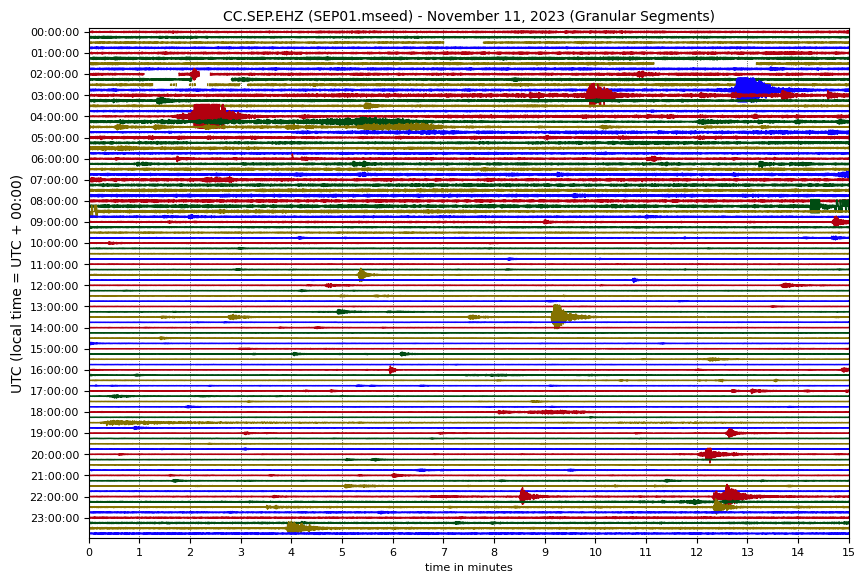
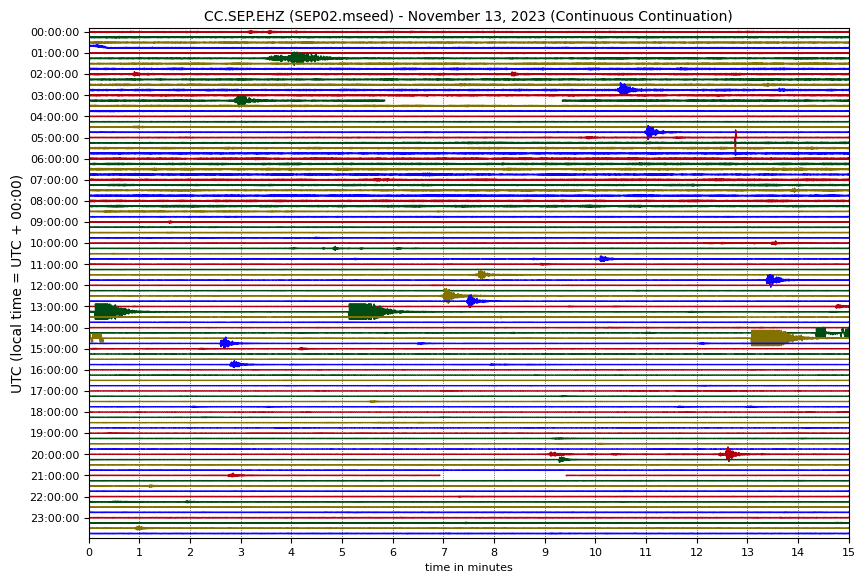
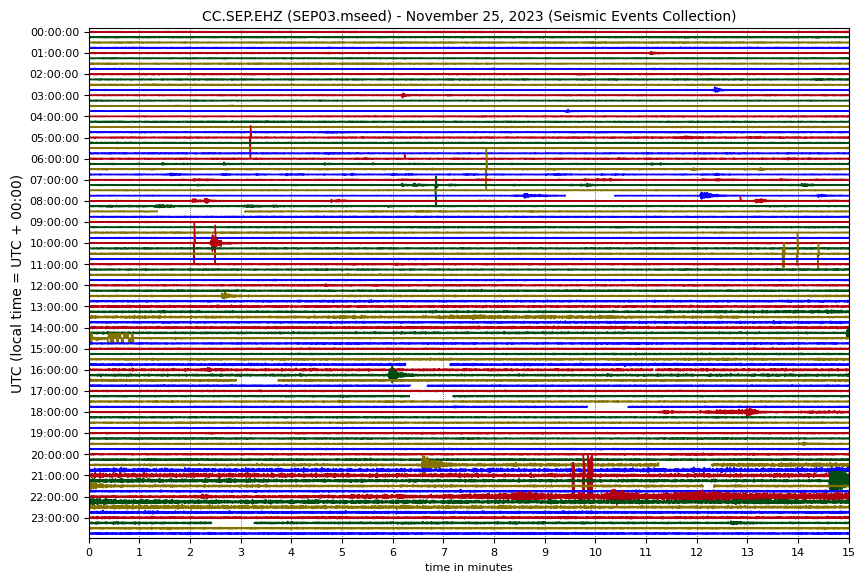

In [73]:
# =====================================================================
# 3. Execution & Combined Dashboard Render
# =====================================================================

analyzer = SeismicAnalyzer("seismic.db")
metadata = analyzer.get_metadata(["SEP01.mseed", "SEP02.mseed", "SEP03.mseed"])
file_class_map = {rec["filename"]: rec["classification"] for rec in metadata}

print("Generating seismic plots...")
plots = {
    "SEP01": VisualsEngine.generate_dayplot_b64(
        "SEP01.mseed", file_class_map["SEP01.mseed"]
    ),
    "SEP02": VisualsEngine.generate_dayplot_b64(
        "SEP02.mseed", file_class_map["SEP02.mseed"]
    ),
    "SEP03": VisualsEngine.generate_dayplot_b64(
        "SEP03.mseed", file_class_map["SEP03.mseed"]
    ),
}

print("Rendering station map...")
map_html = VisualsEngine.build_map(analyzer.fetch_stations())

# Format metadata table elements dynamically
table_rows_html = ""
for rec in metadata:
    table_rows_html += f"""
    <tr style="border-bottom: 1px solid #ccc; color: #111111;">
        <td style="padding: 10px; font-weight: bold;">{rec['filename']}</td>
        <td style="padding: 10px;">{rec['classification']}</td>
        <td style="padding: 10px;">{rec['traces']}</td>
        <td style="padding: 10px;">{rec['avg_samples']}</td>
        <td style="padding: 10px;">{rec['total_samples']}</td>
    </tr>
    """

# Layout Assembly with optimized clean styling
dashboard_html = f"""
<style>
  .outer-container {{ font-family: Arial, sans-serif; max-width: 1000px; margin: 20px auto; }}
  .metadata-card {{ background: #ffffff; border-left: 5px solid #2e86c1; border: 1px solid #e0e0e0; border-left-width: 5px; padding: 20px; margin-bottom: 25px; border-radius: 4px; box-shadow: 0 2px 8px rgba(0,0,0,0.06); }}
  .tab-container {{ border: 1px solid #ccc; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 10px rgba(0,0,0,0.1); background: #fff; }}
  .tab-header {{ background-color: #f1f1f1; display: flex; border-bottom: 1px solid #ccc; }}
  .tab-btn {{ padding: 14px 20px; cursor: pointer; border: none; background: none; font-size: 14px; font-weight: bold; color: #111111; transition: background-color 0.3s, color 0.3s; outline: none; }}
  .tab-btn:hover {{ background-color: #ddd; }}
  .tab-input {{ display: none; }}
  .tab-content {{ display: none; padding: 20px; background: #fff; height: 600px; overflow-y: auto; }}
  #tab1_sub:checked ~ .tab-header label[for="tab1_sub"],
  #tab2_sub:checked ~ .tab-header label[for="tab2_sub"],
  #tab3_sub:checked ~ .tab-header label[for="tab3_sub"],
  #tab4_sub:checked ~ .tab-header label[for="tab4_sub"] {{ background-color: #2e86c1; color: #fff; }}
  #tab1_sub:checked ~ #content-map-sub, #tab2_sub:checked ~ #content-sep01-sub, #tab3_sub:checked ~ #content-sep02-sub, #tab4_sub:checked ~ #content-sep03-sub {{ display: block; }}
  .embed-img {{ display: block; max-width: 100%; height: auto; margin: 0 auto; }}
</style>

<div class="outer-container">
  <div class="metadata-card">
      <h2 style="margin-top: 0; color: #2e86c1; font-weight: bold;">Mount St. Helens Seismic Metadata Dashboard</h2>
      <p style="font-size: 14px; color: #111111; margin-bottom: 15px;">
          Relational records (<code>seismic.db</code>) parsed dynamically from raw waveforms. Review dynamic trace counts and geological characteristics below:
      </p>
      <table style="width: 100%; border-collapse: collapse; text-align: left; font-size: 13px; color: #111111;">
          <thead>
              <tr style="background-color: #eaeded; border-bottom: 2px solid #bbb; color: #111111; font-weight: bold;">
                  <th style="padding: 10px;">File Name</th>
                  <th style="padding: 10px;">Characteristics</th>
                  <th style="padding: 10px;">Total Traces</th>
                  <th style="padding: 10px;">Avg Samples/Trace</th>
                  <th style="padding: 10px;">Total Samples</th>
              </tr>
          </thead>
          <tbody>
              {table_rows_html}
          </tbody>
      </table>
  </div>

  <div class="tab-container">
    <input type="radio" name="dash-tabs-sub" id="tab1_sub" class="tab-input" checked onchange="triggerMapResizeSub()">
    <input type="radio" name="dash-tabs-sub" id="tab2_sub" class="tab-input">
    <input type="radio" name="dash-tabs-sub" id="tab3_sub" class="tab-input">
    <input type="radio" name="dash-tabs-sub" id="tab4_sub" class="tab-input">

    <div class="tab-header">
      <label for="tab1_sub" class="tab-btn">𖧺 Station Map & Info</label>
      <label for="tab2_sub" class="tab-btn">𖧈 SEP01 Helicorder</label>
      <label for="tab3_sub" class="tab-btn">𖧈 SEP02 Helicorder</label>
      <label for="tab4_sub" class="tab-btn">𖧈 SEP03 Helicorder</label>
    </div>

    <div id="content-map-sub" class="tab-content" style="padding: 0; height: 500px;">
      {map_html}
    </div>
    <div id="content-sep01-sub" class="tab-content">
      <h3 style="color:#2e86c1; text-align:center;">SEP01 Waveform Dayplot</h3>
      <img class="embed-img" src="data:image/png;base64,{plots['SEP01']}" alt="SEP01 dayplot">
    </div>
    <div id="content-sep02-sub" class="tab-content">
      <h3 style="color:#2e86c1; text-align:center;">SEP02 Waveform Dayplot</h3>
      <img class="embed-img" src="data:image/png;base64,{plots['SEP02']}" alt="SEP02 dayplot">
    </div>
    <div id="content-sep03-sub" class="tab-content">
      <h3 style="color:#2e86c1; text-align:center;">SEP03 Waveform Dayplot</h3>
      <img class="embed-img" src="data:image/png;base64,{plots['SEP03']}" alt="SEP03 dayplot">
    </div>
  </div>
</div>

<script>
  function triggerMapResizeSub() {{
    setTimeout(function() {{ window.dispatchEvent(new Event("resize")); }}, 200);
  }}
</script>
"""

display(HTML(dashboard_html))